### 1. Load Dataset dan Pembagian Data (70:30)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split dataset: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Standardisasi fitur untuk mengoptimalkan performa Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah data training: {X_train.shape[0]}")
print(f"Jumlah data testing: {X_test.shape[0]}")

Jumlah data training: 398
Jumlah data testing: 171


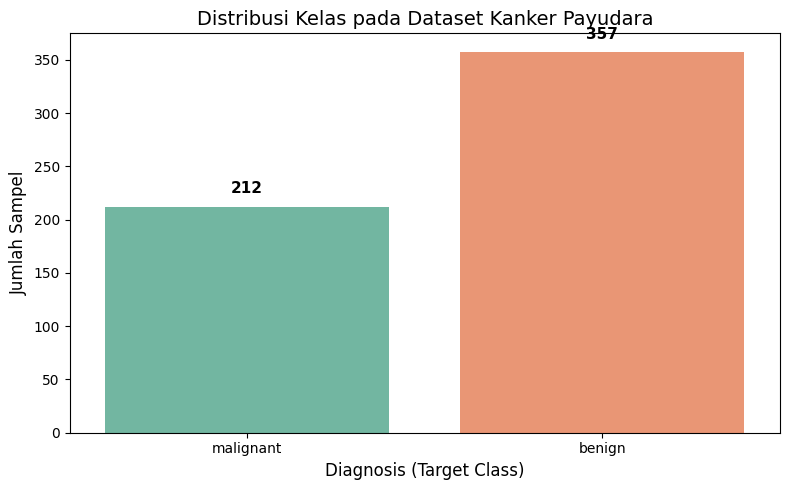

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Menghitung distribusi kelas
unique, counts = np.unique(y, return_counts=True)
class_counts = dict(zip(data.target_names, counts))

# Membuat bar plot
plt.figure(figsize=(8, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="Set2", hue=list(class_counts.keys()), legend=False)

# Menambahkan label dan judul
plt.title("Distribusi Kelas pada Dataset Kanker Payudara", fontsize=14)
plt.xlabel("Diagnosis (Target Class)", fontsize=12)
plt.ylabel("Jumlah Sampel", fontsize=12)

# Menampilkan nilai di atas setiap batang
for i, val in enumerate(class_counts.values()):
    plt.text(i, val + 10, str(val), ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 2. Pelatihan Model dan Evaluasi

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Inisialisasi Model
lr_model = LogisticRegression(max_iter=10000, random_state=42)
rf_model = RandomForestClassifier(random_state=42)

# 2. Fit Model
lr_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)  # Random Forest tidak sensitif terhadap skala fitur

# 3. Prediksi
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

# 4. Kalkulasi Akurasi
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Logistic Regression : {acc_lr:.4f}")
print(f"Akurasi Random Forest       : {acc_rf:.4f}")

Akurasi Logistic Regression : 0.9883
Akurasi Random Forest       : 0.9357


### 3. Visualisasi Confusion Matrix

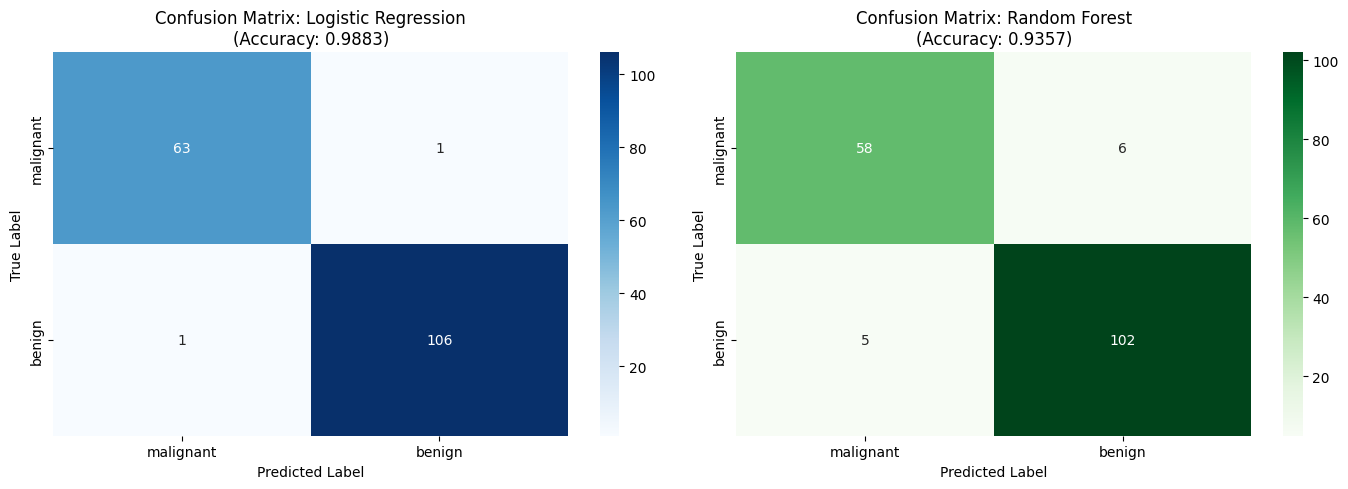

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=data.target_names, yticklabels=data.target_names)
ax[0].set_title(f'Confusion Matrix: Logistic Regression\n(Accuracy: {acc_lr:.4f})')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

# Confusion Matrix - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=ax[1],
            xticklabels=data.target_names, yticklabels=data.target_names)
ax[1].set_title(f'Confusion Matrix: Random Forest\n(Accuracy: {acc_rf:.4f})')
ax[1].set_xlabel('Predicted Label')
ax[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### 4. Laporan Klasifikasi Detail

In [4]:
print("=== LAPORAN KLASIFIKASI: LOGISTIC REGRESSION ===")
print(classification_report(y_test, y_pred_lr, target_names=data.target_names))

print("\n=== LAPORAN KLASIFIKASI: RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf, target_names=data.target_names))

=== LAPORAN KLASIFIKASI: LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


=== LAPORAN KLASIFIKASI: RANDOM FOREST ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



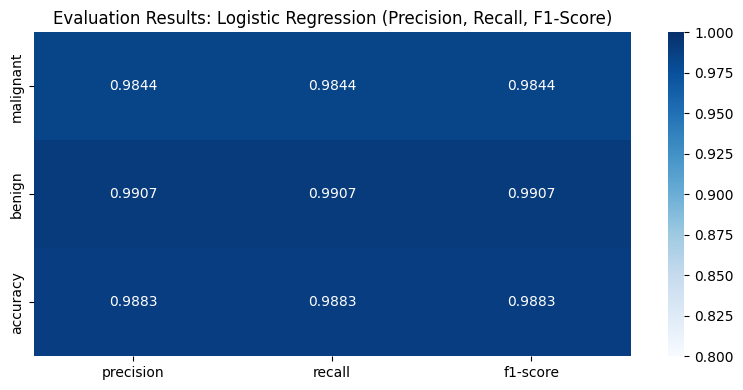

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Membuat classification report dalam bentuk dictionary
report_lr = classification_report(y_test, y_pred_lr, target_names=data.target_names, output_dict=True)
report_rf = classification_report(y_test, y_pred_rf, target_names=data.target_names, output_dict=True)

# Ubah ke DataFrame agar mudah di-plot
df_lr = pd.DataFrame(report_lr).iloc[:-1, :3].T # Ambil precision, recall, f1-score

# Plot heatmap untuk Evaluation Results Logistic Regression
plt.figure(figsize=(8, 4))
sns.heatmap(df_lr, annot=True, cmap='Blues', fmt='.4f', vmin=0.8, vmax=1.0)
plt.title('Evaluation Results: Logistic Regression (Precision, Recall, F1-Score)')
plt.tight_layout()
plt.savefig('evaluation_results.png') # File akan otomatis tersimpan di Colab!
plt.show()

### 5. Analisis Hasil

#### **Analisis Pemilihan Model Terbaik**
*Berdasarkan hasil uji program, perbandingan performa kedua model dapat diamati melalui poin-poin berikut:*

Model yang paling aman secara klinis adalah model dengan jumlah False Negative (FN) paling sedikit, yaitu kasus pasien kanker ganas (malignant) yang keliru diprediksi sebagai jinak (benign).

#### **Mengapa Akurasi Saja Tidak Cukup dalam Kasus Kanker**
Dalam bidang medis, penggunaan metrik akurasi murni berisiko menyesatkan karena dua alasan utama:

1. **Data yang Tidak Seimbang (Imbalanced Data):** Misalkan data terdiri dari 95% kasus jinak dan 5% kasus ganas; model yang secara asal selalu menebak "jinak" tetap akan menghasilkan akurasi tinggi (95%), padahal gagal mendeteksi seluruh penderita kanker.
2. **Risiko Kesalahan Prediksi:**
   - **False Positive (FP):** Pasien sehat dikira sakit—meski memicu kepanikan atau biaya tes tambahan, keselamatan pasien tetap terjaga.
   - **False Negative (FN):** Pasien sakit justru diprediksi sehat—kondisi ini sangat berbahaya dan berakibat fatal karena pasien kehilangan kesempatan mendapatkan penanganan medis.

**Kesimpulan Evaluasi:** Guna memaksimalkan deteksi kasus positif kanker, fokus utama evaluasi harus dialihkan pada nilai Recall dan F1-Score yang jauh lebih esensial daripada sekadar melihat tingkat Accuracy.